/opt/homebrew/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Sample rate: 44100 Hz, Duration: 24.01 seconds


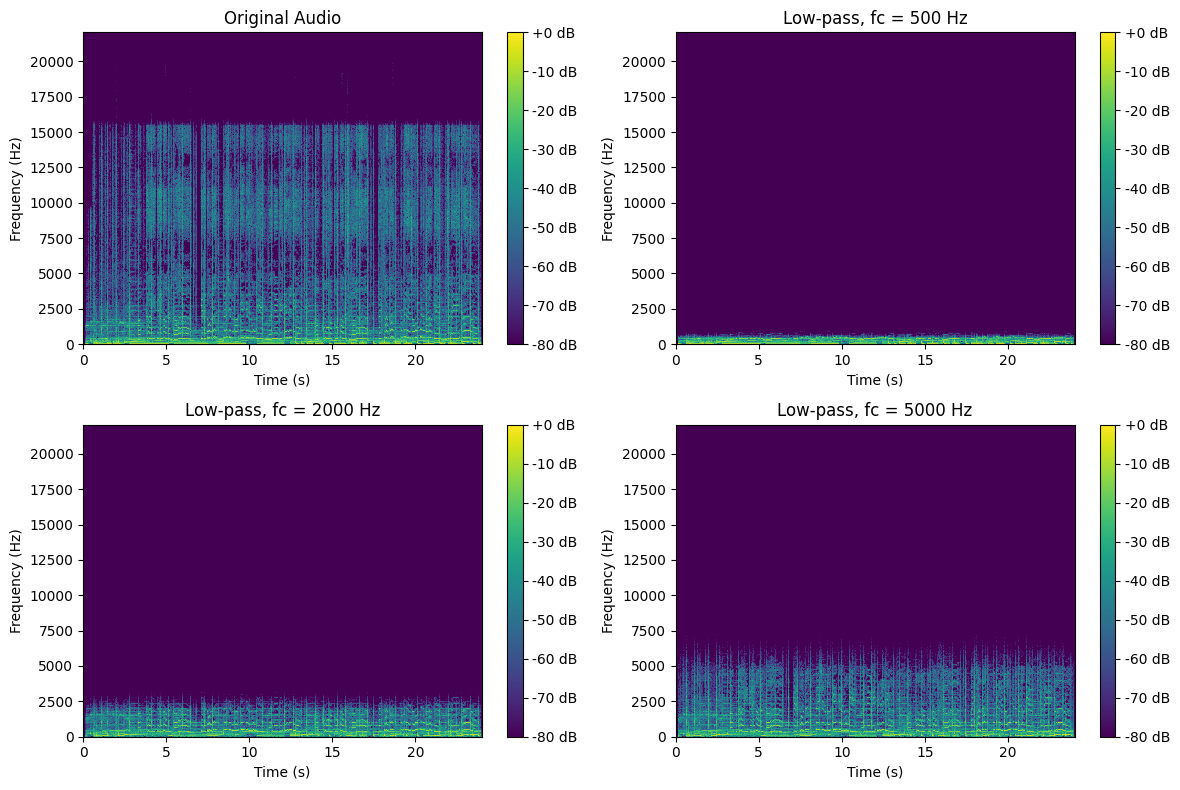

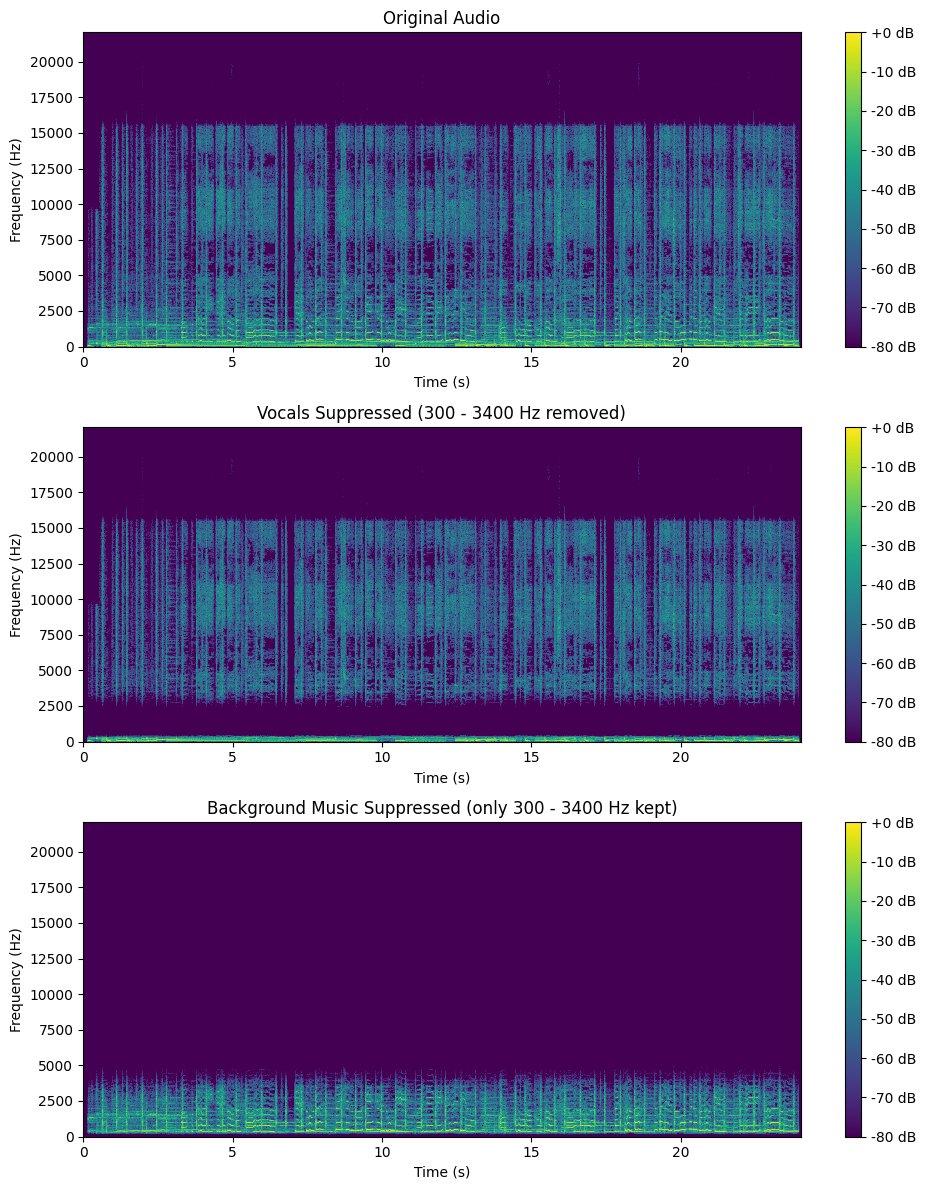

In [3]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import butter, sosfiltfilt

# --- 1. Load the MP3 song ---
filename = '/Users/krishsondagar/Krish/sem_5/DSIP/labs/ope2/audios/audio1.wav'
y, sr = librosa.load(filename, sr=None)
print(f"Sample rate: {sr} Hz, Duration: {len(y)/sr:.2f} seconds")

# --- 2. Filter functions (Butterworth, zero-phase) ---
def lowpass(data, cutoff, fs, order=6):
    sos = butter(order, cutoff, btype='low', fs=fs, output='sos')
    return sosfiltfilt(sos, data)

def bandpass(data, low, high, fs, order=6):
    sos = butter(order, [low, high], btype='band', fs=fs, output='sos')
    return sosfiltfilt(sos, data)

def save_mp3(name, data):
    # scale down only if the signal would clip, then write as MP3
    sf.write(name, data / max(1, np.max(np.abs(data))), sr)

def plot_spectrograms(signals, titles, rows, cols, figsize):
    plt.figure(figsize=figsize)
    for i, (sig, title) in enumerate(zip(signals, titles)):
        plt.subplot(rows, cols, i+1)
        D = librosa.amplitude_to_db(np.abs(librosa.stft(sig)), ref=np.max)
        librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='hz', cmap='viridis')
        plt.colorbar(format='%+2.0f dB')
        plt.title(title)
        plt.xlabel('Time (s)')
        plt.ylabel('Frequency (Hz)')
    plt.tight_layout()
    plt.show()

# --- 3. (a) Low-pass filter with three different cutoff frequencies ---
cutoffs = [500, 2000, 5000]
lp_outputs = []
for fc in cutoffs:
    out = lowpass(y, fc, sr)
    lp_outputs.append(out)
    save_mp3(f'lowpass_{fc}Hz.mp3', out)

plot_spectrograms([y] + lp_outputs,
                  ['Original Audio'] + [f'Low-pass, fc = {fc} Hz' for fc in cutoffs],
                  2, 2, (12, 8))

# --- 4. (b) Band-pass filter (300 - 3400 Hz, vocal range) ---
vocal_band = bandpass(y, 300, 3400, sr)

vocals_suppressed = y - vocal_band       # removes the vocal band -> background music
music_suppressed = vocal_band            # keeps only the vocal band -> background suppressed

save_mp3('vocals_suppressed.mp3', vocals_suppressed)
save_mp3('music_suppressed.mp3', music_suppressed)

plot_spectrograms([y, vocals_suppressed, music_suppressed],
                  ['Original Audio', 'Vocals Suppressed (300 - 3400 Hz removed)',
                   'Background Music Suppressed (only 300 - 3400 Hz kept)'],
                  3, 1, (10, 12))